# Projet Data science
## Auteur: Sehli Mouad
## Date: 01/11/2025



# Analyse de données 


On va d'abord commencer par analyser les données en utilisant la class dataprocessor

In [10]:
import importlib
from dataprocessor import * 
import func_utils
from modeltrainer import * 
from func_utils import *
import dataprocessor
import modeltrainer
importlib.reload(modeltrainer)
importlib.reload(dataprocessor)
importlib.reload(func_utils)
from dataprocessor import *
from modeltrainer import * 
from func_utils import *

Xtrain_molecular: str = r"./data/molecular_train.csv"
Xtrain_clinical: str = r"./data/clinical_train.csv"
target_train: str = r"./data/target_train.csv"

data_train_mol: pd.DataFrame = pd.read_csv(Xtrain_molecular)
data_train_cli: pd.DataFrame = pd.read_csv(Xtrain_clinical)
target_df: pd.DataFrame = pd.read_csv(target_train)

# Convert 'OS_YEARS' to numeric, forcing errors to NaN 

target_df['OS_YEARS'] = pd.to_numeric(target_df['OS_YEARS'], errors='coerce')

# Ensure 'OS_STATUS' is boolean
target_df['OS_STATUS'] = target_df['OS_STATUS'].astype(bool)

data = DataProcessor(data_train_mol, data_train_cli, target_df)

In [ ]:
variable_frequency_table(data.clinical_data)

,Variable,Unique_Value,Frequency,Percentage
0,ID,P132697,1,0.03%
1,ID,P132698,1,0.03%
2,ID,P116889,1,0.03%
3,ID,P132699,1,0.03%
4,ID,P132700,1,0.03%
...,...,...,...,...
7840,CYTOGENETICS,"45,x,-y[16]/46,xy[14]",1,0.03%
7841,CYTOGENETICS,"44-45,xy,-5,der(6)del(6)(?q13q15)t(6;15)(p25;p...",1,0.03%
7842,CYTOGENETICS,"46,xx,del(5)(q13q33)[12]/46,xx[8]",1,0.03%
7843,CYTOGENETICS,"47,xx,+15[3]/46,xx[17]",1,0.03%


In [24]:
filter_variables_by_mutual_info(data.merged_table.drop(columns="ID").columns.tolist(), data.merged_table.drop(columns="ID").dropna(), target="OS_YEARS", mi_threshold=0.1)

ValueError: could not convert string to float: 'X'

In [21]:
data.merged_table

,ID,CHR,START,END,REF,ALT,GENE,PROTEIN_CHANGE,EFFECT,VAF,...,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,CYTOGENETICS,OS_YEARS,OS_STATUS
0,P100000,11,119149248.0,119149248.0,G,A,CBL,p.C419Y,non_synonymous_codon,0.0830,...,IHBT,3.0,7.50,4.65,NaN,8.80,406.0,"46,xx,del(5)(q15q33.3)[3]/46,xx[1]",5.819178,False
1,P100000,5,131822301.0,131822301.0,G,T,IRF1,p.Y164*,stop_gained,0.0220,...,IHBT,3.0,7.50,4.65,NaN,8.80,406.0,"46,xx,del(5)(q15q33.3)[3]/46,xx[1]",5.819178,False
2,P100000,3,77694060.0,77694060.0,G,C,ROBO2,p.?,splice_site_variant,0.4100,...,IHBT,3.0,7.50,4.65,NaN,8.80,406.0,"46,xx,del(5)(q15q33.3)[3]/46,xx[1]",5.819178,False
3,P100000,4,106164917.0,106164917.0,G,T,TET2,p.R1262L,non_synonymous_codon,0.4300,...,IHBT,3.0,7.50,4.65,NaN,8.80,406.0,"46,xx,del(5)(q15q33.3)[3]/46,xx[1]",5.819178,False
4,P100000,2,25468147.0,25468163.0,ACGAAGAGGGGGTGTTC,A,DNMT3A,p.E505fs*141,frameshift_variant,0.0898,...,IHBT,3.0,7.50,4.65,NaN,8.80,406.0,"46,xx,del(5)(q15q33.3)[3]/46,xx[1]",5.819178,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10930,P131472,NaN,NaN,NaN,NaN,NaN,MLL,MLL_PTD,PTD,NaN,...,TUD,17.5,8.57,5.90,0.65,11.52,16.0,"46,xy,del(20)(q)",0.671233,False
10931,P131505,NaN,NaN,NaN,NaN,NaN,MLL,MLL_PTD,PTD,NaN,...,TUD,8.0,3.20,NaN,NaN,10.34,66.0,"45,x,-y/46,xy",3.695890,False
10932,P131816,NaN,NaN,NaN,NaN,NaN,MLL,MLL_PTD,PTD,NaN,...,KI,18.0,34.20,4.80,19.40,8.00,155.0,"46,xx[20]",0.468493,True
10933,P132717,NaN,NaN,NaN,NaN,NaN,MLL,MLL_PTD,PTD,NaN,...,MSK,15.0,1.80,0.60,0.10,8.90,51.0,"46,xx[20]trisomy8onfish",3.589041,True


Commençons par décrire brievement la base de données dont on dispose : 

## Données Cliniques (Une Ligne par Patient)

Chaque patient est associé à un identifiant unique et à des informations cliniques détaillées :

* **ID :** Identifiant unique pour chaque patient.
* **CENTER :** Le centre clinique où le patient est traité.
* **BM_BLAST :** Pourcentage de blastes dans la moelle osseuse, indiquant la proportion de cellules sanguines anormales trouvées dans la moelle osseuse des patients.
* **WBC :** Nombre de globules blancs (White Blood Cell count), mesuré en Giga/L (paramètre de l'hémogramme).
* **ANC :** Nombre absolu de neutrophiles (Absolute Neutrophil Count) dans le sang, en Giga/L (paramètre de l'hémogramme).
* **MONOCYTES :** Nombre de monocytes dans le sang, en Giga/L (paramètre de l'hémogramme).
* **HB :** Taux d'hémoglobine, mesuré en g/dL (paramètre de l'hémogramme).
* **PLT :** Nombre de plaquettes (Platelet count), en Giga/L (paramètre de l'hémogramme).
* **CYTOGENETICS :** Description détaillée du caryotype du patient, représentant les anomalies chromosomiques détectées dans les cellules cancéreuses du sang. Les notations suivent la norme ISCN, avec des marqueurs typiques comme "46,XX" pour un caryotype féminin normal ou "46,XY" pour un caryotype masculin normal. Des anomalies comme la monosomie 7 (perte du chromosome 7) indiquent une maladie à plus haut risque.


## Données Moléculaires des Gènes (Une Ligne par Mutation Somatique par Patient)

Les mutations somatiques (acquises) sont des mutations spécifiques aux cellules cancéreuses, non trouvées dans les cellules normales du patient. Ces données capturent les mutations génétiques au niveau cellulaire :

* **ID :** Identifiant unique pour chaque patient.
* **CHR, START, END :** Position chromosomique de la mutation sur le génome humain.
* **REF, ALT :** Le nucléotide de référence et le nucléotide alternatif (mutant).
* **GENE :** Le gène affecté par la mutation.
* **PROTEIN_CHANGE :** L'impact de la mutation sur la protéine produite par le gène.
* **EFFECT :** Classification générale de l'impact de la mutation sur la fonction du gène.
* **VAF :** Fraction allélique de la variante (Variant Allele Fraction), représentant la proportion de cellules portant la mutation.

## Données target : 
* **OS_STATUS**: Statut du patient (mort/vivant) à la dernière consultation
* **OS_YEARS** : Combien d'années le patient a vécu jusqu'à maintenant

In [ ]:
data.show()

Molecular Data :
        ID CHR        START          END                REF ALT    GENE  \
0  P100000  11  119149248.0  119149248.0                  G   A     CBL   
1  P100000   5  131822301.0  131822301.0                  G   T    IRF1   
2  P100000   3   77694060.0   77694060.0                  G   C   ROBO2   
3  P100000   4  106164917.0  106164917.0                  G   T    TET2   
4  P100000   2   25468147.0   25468163.0  ACGAAGAGGGGGTGTTC   A  DNMT3A   

  PROTEIN_CHANGE                EFFECT     VAF   DEPTH  
0        p.C419Y  non_synonymous_codon  0.0830  1308.0  
1        p.Y164*           stop_gained  0.0220   532.0  
2            p.?   splice_site_variant  0.4100   876.0  
3       p.R1262L  non_synonymous_codon  0.4300   826.0  
4   p.E505fs*141    frameshift_variant  0.0898   942.0  

Clinical Data :
        ID CENTER  BM_BLAST    WBC  ANC  MONOCYTES    HB    PLT  \
0  P132697    MSK      14.0    2.8  0.2        0.7   7.6  119.0   
1  P132698    MSK       1.0    7.4  2.4

## Traitement variable quantitatives

On va commencer par traiter nos données quantitatives 

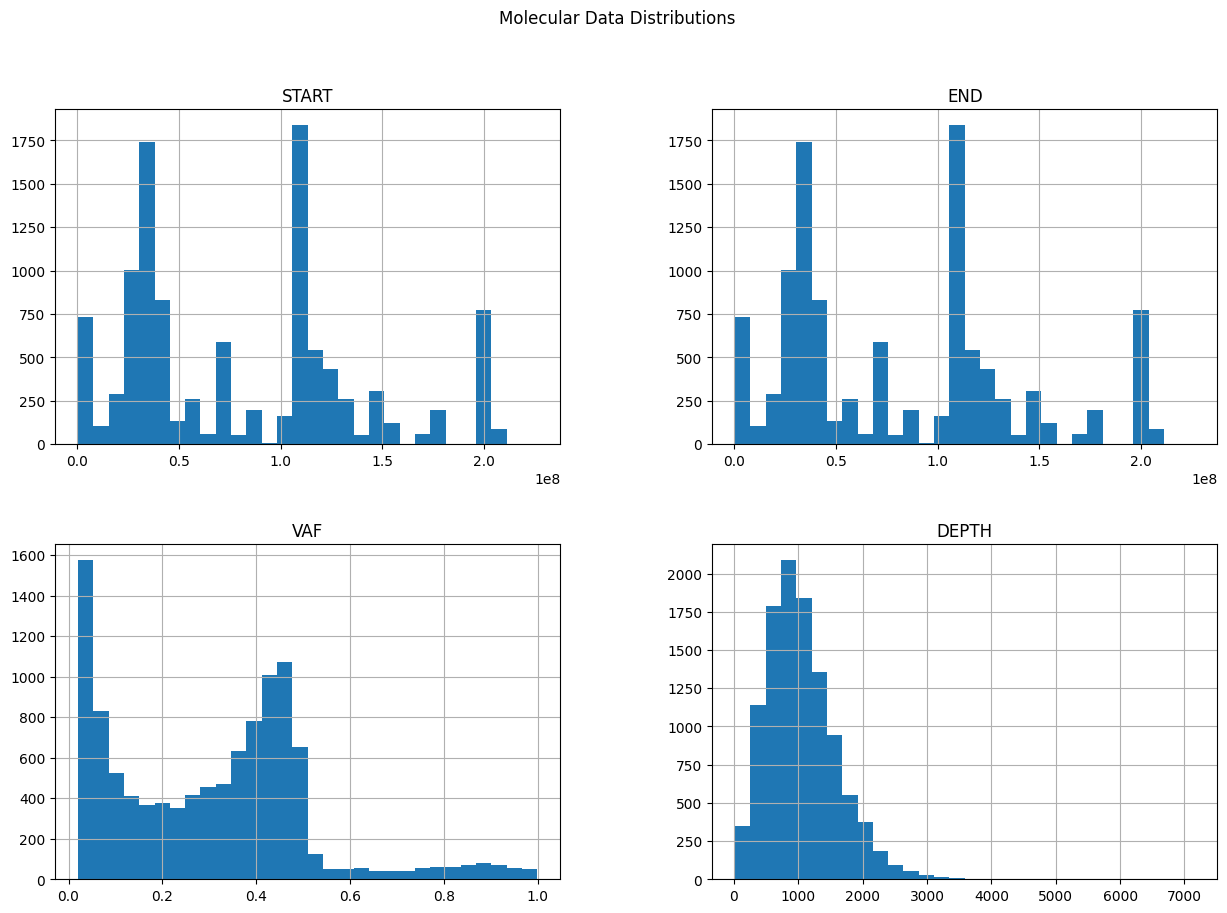

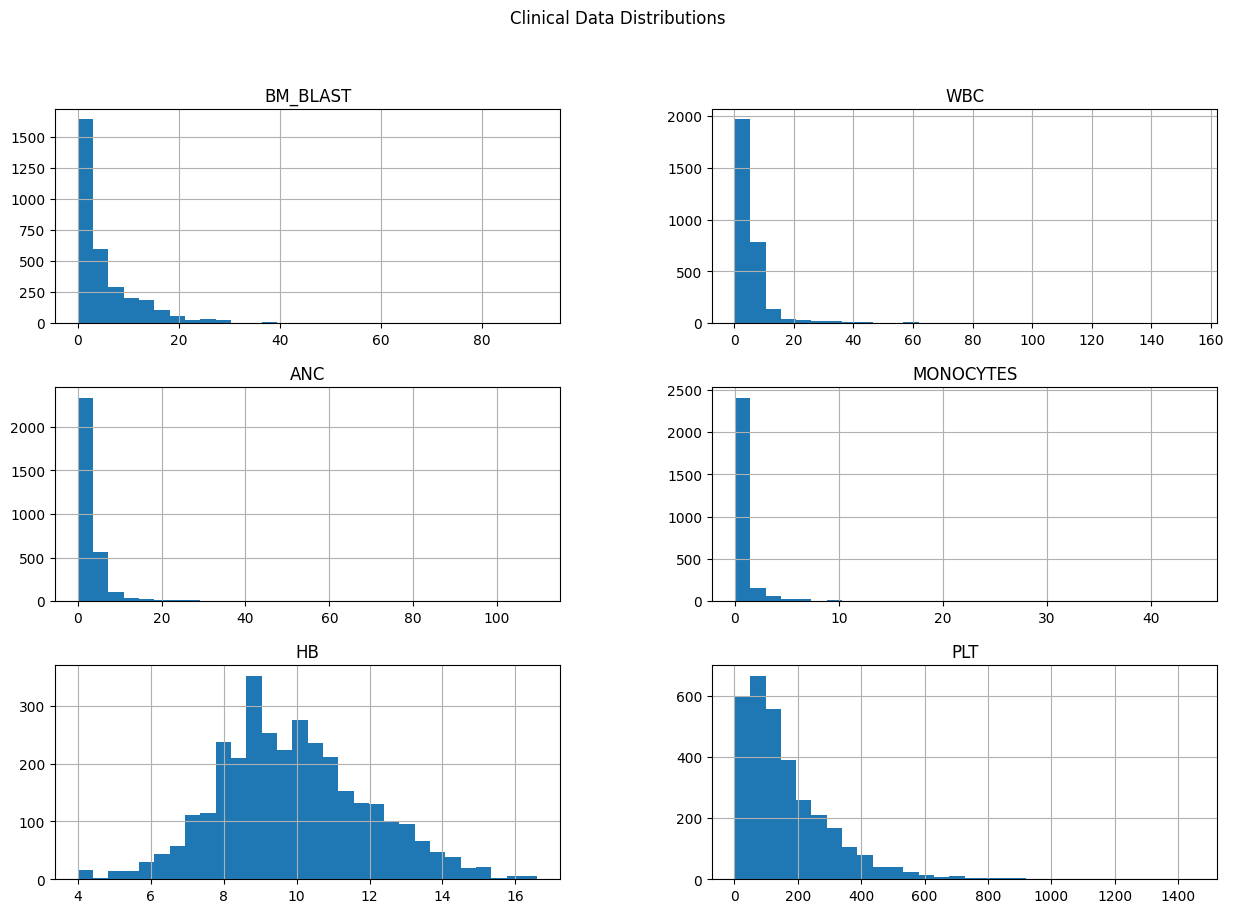

In [ ]:
data.plot_quant_var()

Pour les valeurs manquantes, on peut voir que pour HB et Depth des bons candidats seraient de simuler des lois gaussiennes, pour vérifier ces hypothèses on dessiner un QQplot

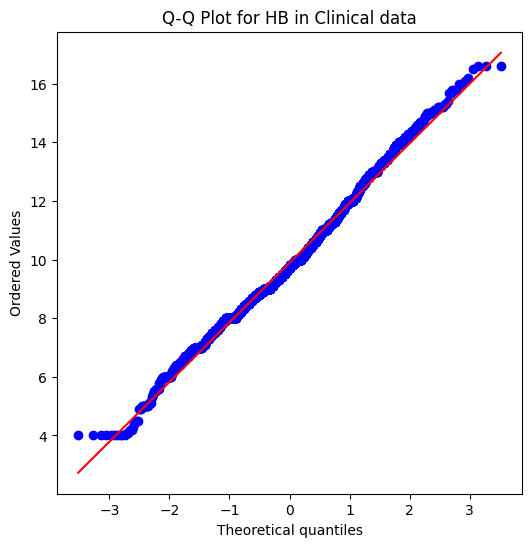

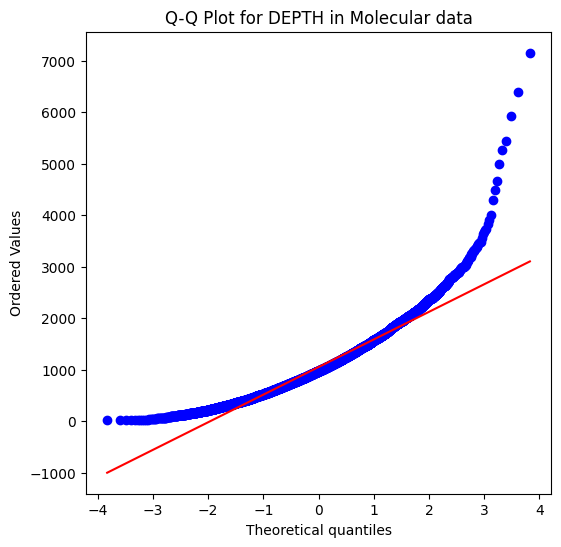

In [ ]:
data.qqplot_quant_var(["HB","DEPTH"])

On peut voir qu'à part pour les outliers, on peut faire l'hypothèse que les données HB sont bel et biens gaussiens.
On rejette l'hypothèse pour la variable DEPTH. on va remplacer les valeurs manquantes


In [ ]:
# Vérifier les valeurs manquantes avant remplacement
print(f"Valeurs manquantes avant: {data_train_cli['HB'].isna().sum()}")

# Simuler les valeurs pour remplacer les NaN
n_missing = data_train_cli["HB"].isna().sum()
valeurs_manquantes = data.simulate_values("HB", n_missing)

# Remplacer les valeurs manquantes (méthode correcte)
mask = data_train_cli["HB"].isna()
data_train_cli.loc[mask, "HB"] = list(valeurs_manquantes["HB"])

# Vérifier que les valeurs manquantes ont été remplacées
print(f"Valeurs manquantes après: {data_train_cli['HB'].isna().sum()}")

Valeurs manquantes avant: 110
Valeurs manquantes après: 0


## Données moleculaires 

On va créer une variable danger qui est le produit de la variable VAF et DEPTH et désigner le danger la mutation (on va dire qu'une mutation est plus dangereuse si elle est plus profonde et la frequence de variation est plus elevés)
une fois qu'on a fait ça on va aggreger en utilisant l'encodage binaire pour les genes et les effets 

In [ ]:
data.add_danger()
data.aggregate_genes()
data.temporary.head()

,ID,DANGER,GENE_ABL1,GENE_ARID1A,GENE_ARID2,GENE_ASXL1,GENE_ASXL2,GENE_ATRX,GENE_BAP1,GENE_BCL10,...,EFFECT_inframe_codon_gain,EFFECT_inframe_codon_loss,EFFECT_inframe_variant,EFFECT_initiator_codon_change,EFFECT_non_synonymous_codon,EFFECT_splice_site_variant,EFFECT_stop_gained,EFFECT_stop_lost,EFFECT_stop_retained_variant,EFFECT_synonymous_codon
0,P100000,1323.4786,False,False,False,False,False,False,False,False,...,False,False,False,False,True,True,True,False,False,False
1,P100001,271.2100,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,True,False,False,False
2,P100002,351.8090,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,True,False,False,False
3,P100004,607.9536,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,P100006,490.1980,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,True,False,False,False


Comme on peut le voir on a un très grand problème de dimensionnalité donc on va voiloir réduire ses variables, pour se faire on va étudier leurs impacts ainsi que leurs fréquences, on va considerer que si une variable est presente moins de 10 % des cas, sa fréquence n'est pas significatif pour l'inclure, par la suite nous allons étudier leur significativité 

In [ ]:
frequent_dummies = data.get_frequency()
show_frequency_table(data,frequent_dummies)

Variables avec valeurs positives > 10% des cas: 21
Total de variables (avec ID): 164
Réduction: 143 variables supprimées

Top 20 variables les plus fréquentes:
                       Variable  Positive_Frequency_%   Total_Sum  Max_Value
0                        DANGER                 99.93  3376209.12  7191.7635
1   EFFECT_non_synonymous_codon                 88.43     2676.00       True
2     EFFECT_frameshift_variant                 56.51     1710.00       True
3            EFFECT_stop_gained                 39.49     1195.00       True
4                         CHR_2                 38.96     1179.00       True
5                        CHR_17                 36.85     1115.00       True
6                         CHR_4                 34.80     1053.00       True
7                     GENE_TET2                 34.14     1033.00       True
8                        CHR_20                 30.63      927.00       True
9                    GENE_ASXL1                 29.51      893.00     

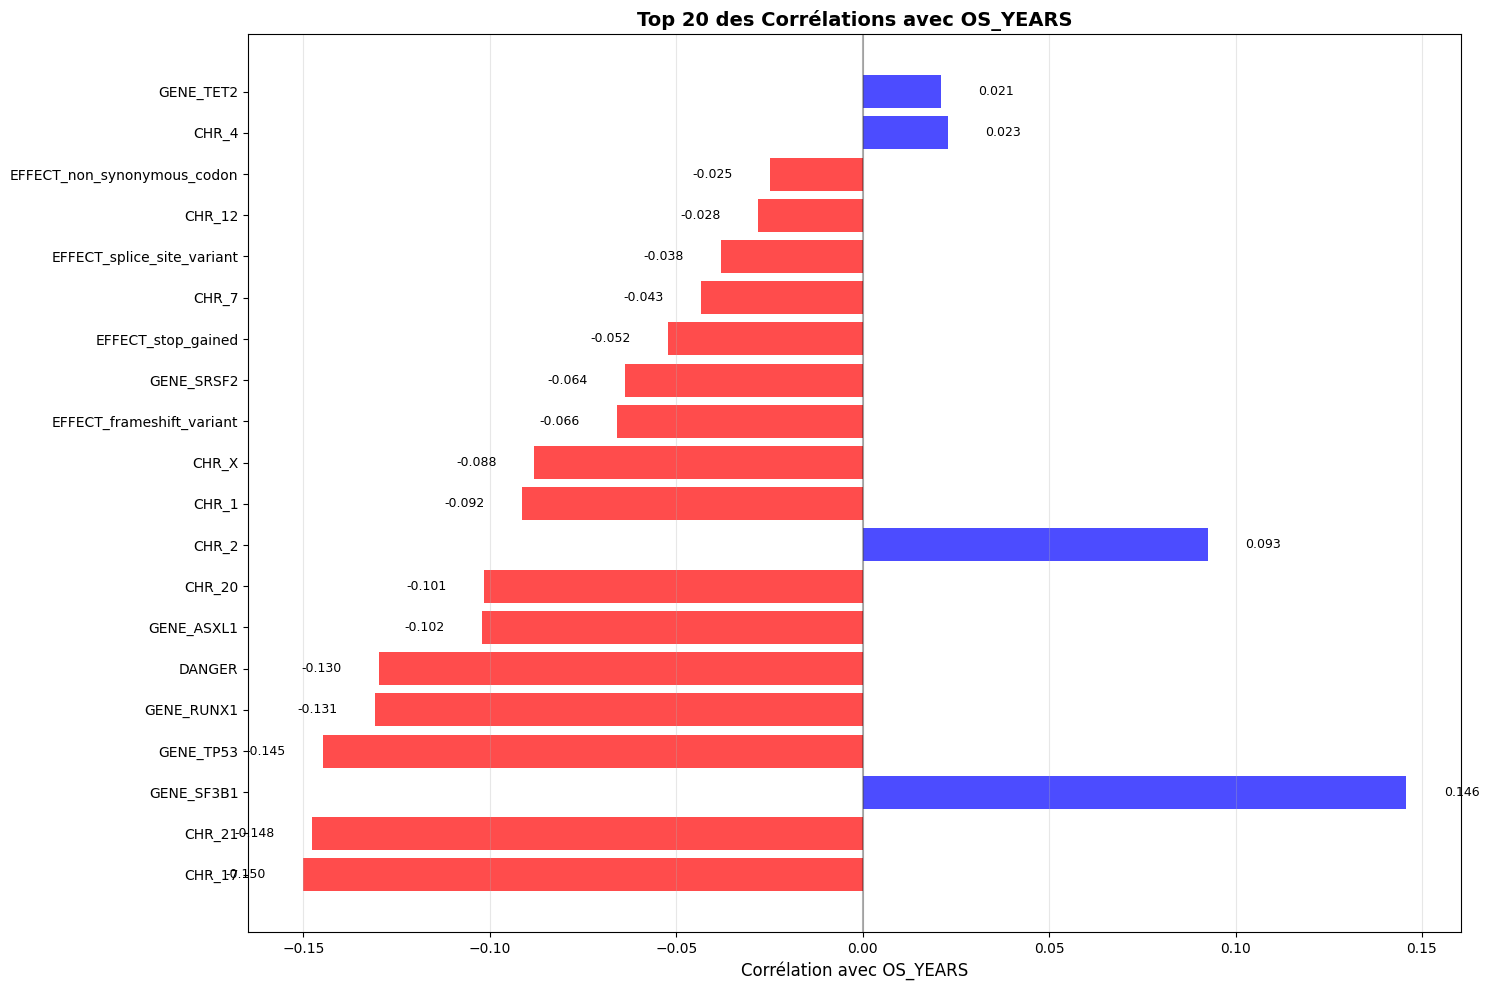

=== Corrélations avec OS_YEARS ===
Nombre total de variables: 21
Corrélation moyenne: -0.054
Corrélation médiane: -0.064
Corrélation max (absolue): 0.150

Corrélations fortes (|r| > 0.1): 8 variables
  CHR_17: -0.150
  CHR_21: -0.148
  GENE_SF3B1: 0.146
  GENE_TP53: -0.145
  GENE_RUNX1: -0.131
  DANGER: -0.130
  GENE_ASXL1: -0.102
  CHR_20: -0.101


CHR_17                        -0.150031
CHR_21                        -0.147754
GENE_SF3B1                     0.145803
GENE_TP53                     -0.144726
GENE_RUNX1                    -0.130787
DANGER                        -0.129705
GENE_ASXL1                    -0.102230
CHR_20                        -0.101481
CHR_2                          0.092675
CHR_1                         -0.091515
CHR_X                         -0.088091
EFFECT_frameshift_variant     -0.066013
GENE_SRSF2                    -0.063792
EFFECT_stop_gained            -0.052187
CHR_7                         -0.043410
EFFECT_splice_site_variant    -0.038056
CHR_12                        -0.028077
EFFECT_non_synonymous_codon   -0.024751
CHR_4                          0.022764
GENE_TET2                      0.020903
GENE_DNMT3A                   -0.005971
Name: OS_YEARS, dtype: float64

In [ ]:
corr = correlation(data,frequent_dummies)
plot_correlation(corr,"OS_YEARS")

On va donc garder dans un premier lieu les genes avec une corrélation élevée, on peut aussi faire la remarque que la variable Danger qu'on a introduite est pertinente puisqu'elle a une des corrélations les plus élevées.
  

In [ ]:
variables_importantes = ['ID',
    'CHR_17', 'CHR_21', 'GENE_SF3B1', 'GENE_TP53', 
    'GENE_RUNX1', 'DANGER', 'GENE_ASXL1', 'CHR_20'
]

data.set_molecular_data(data.temporary[variables_importantes])
data.merge_tables()

In [ ]:
data.merged_table.dropna()
data.merged_table.drop(columns="CYTOGENETICS")

,ID,CHR_17,CHR_21,GENE_SF3B1,GENE_TP53,GENE_RUNX1,DANGER,GENE_ASXL1,CHR_20,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,OS_YEARS,OS_STATUS
0,P100000,False,False,False,False,False,1323.4786,False,False,IHBT,3.0,7.50,4.65,NaN,8.8,406.0,5.819178,False
1,P100001,False,False,False,False,False,271.2100,False,False,IHBT,2.0,7.21,2.88,NaN,9.8,364.0,2.857534,False
2,P100002,True,False,False,True,False,351.8090,False,False,IHBT,15.0,2.60,0.49,NaN,8.9,35.0,0.306849,True
3,P100004,False,False,False,False,False,607.9536,False,False,IHBT,3.0,2.55,1.56,NaN,7.0,708.0,5.186301,False
4,P100006,True,False,False,False,False,490.1980,False,False,IHBT,1.0,1.23,0.48,NaN,7.6,105.0,4.917808,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3021,P132725,False,True,False,False,False,4365.4240,True,True,MSK,12.0,2.00,0.60,0.2,11.5,61.0,4.290411,False
3022,P132726,False,False,False,False,False,347.0100,False,False,MSK,15.0,1.90,0.50,0.0,11.2,383.0,2.279452,False
3023,P132727,False,False,False,False,False,816.5240,True,True,MSK,5.0,2.30,1.00,0.4,11.3,44.0,0.578082,False
3024,P132728,False,True,False,False,False,2989.9348,False,False,MSK,2.0,44.90,40.10,2.3,8.2,14.0,1.284932,True


On va donc utiliser ce dataset pour un premier entrainement de notre modèle avec une regression logistique 

In [ ]:
final_data = data.merged_table.dropna()


La fonction generatepairs, genere des pairs d'observations pour entrainer notre modèle

In [ ]:

final_data_model = generate_pairs(final_data.drop(columns=["ID","OS_YEARS","OS_STATUS","CYTOGENETICS","CENTER","ANC","WBC","MONOCYTES"]), final_data[["OS_STATUS","OS_YEARS"]], 1000000, mode = "concat")

c:\Users\U2XF83\Desktop\ISFA M2\Projet Data Science\ProjectDataScienceISFA\dataprocessor.py:349: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if Y.iloc[i][1] >= Y.iloc[j][1]:
c:\Users\U2XF83\Desktop\ISFA M2\Projet Data Science\ProjectDataScienceISFA\dataprocessor.py:368: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if Y.iloc[i][1] <= Y.iloc[j][1]:
c:\Users\U2XF83\Desktop\ISFA M2\Projet Data Science\ProjectDataScienceISFA\dataprocessor.py:369: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behav

In [ ]:
x,y = final_data_model

In [ ]:
#avec nouveau pair 
model = model_ml(x,y)
test =  model.logistic_regression()

Division des données en cours...
=== RÉSULTATS DE LA RÉGRESSION LOGISTIQUE ===
Taille du dataset: 546350 échantillons
Nombre de features: 22
Train set: 437080 échantillons
Test set: 109270 échantillons

=== TABLEAU DE COMPARAISON ===
 Métrique  Train   Test Différence (Train-Test)
 Accuracy 0.7281 0.7305                 -0.0025
Precision 0.7280 0.7305                 -0.0025
   Recall 0.7281 0.7305                 -0.0025
 F1-Score 0.7280 0.7304                 -0.0024
  ROC-AUC 0.8028 0.8048                 -0.0020

=== MATRICES DE CONFUSION ===
Train:
[[166684  57208]
 [ 61655 151533]]

Test:
[[41815 14049]
 [15398 38008]]

=== IMPORTANCE DES FEATURES (Top 10) ===
   Feature  Coefficient  Abs_Coefficient
Feature_20    -0.461460         0.461460
 Feature_9     0.455372         0.455372
Feature_14     0.358904         0.358904
Feature_19     0.307977         0.307977
Feature_16     0.306994         0.306994
 Feature_3    -0.290058         0.290058
Feature_21    -0.246059         0.2460

In [ ]:
from sklearn.isotonic import IsotonicRegression
x_iso = test["y_test_proba"]
y_iso = test["y_test_binary"]
iso_reg = IsotonicRegression().fit(x_iso, y_iso)
x_train = test["y_train_proba"]
